# Self Concept Literature - Network Analysis

This notebook builds publication-ready static questionnaire validity/correlation network figures from `tier1_validity_extraction.xlsx`.

The default node universe is defined by questionnaires/scales appearing in `focal_questionnaire`. A small, explicit exception set is added from `related_questionnaire` because these scales are theoretically relevant to the manuscript figure:

- `(PSCQ): Past Self-Continuity Questionnaire`
- `(ES): Essentialist Beliefs about Human Kinds Scale`
- `(IPTheory - S): Implicit person theory measure - specific abilities`

Rows where `related_questionnaire` points to other outside instruments are excluded from the graph and saved for QA.


## 1. Load the Workbook and Validate Columns

The workbook is loaded with pandas. Column names are normalized only for minor spelling/case/spacing differences. Major missing columns stop the notebook with a clear error.


In [1]:
from pathlib import Path
from collections import Counter
import math
import re
import textwrap

import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

GRAPH_TITLE = "Self concept literature - network analysis"
INPUT_FILENAME = "tier1_validity_extraction.xlsx"
PREFERRED_SHEET = "validity_edges"

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / INPUT_FILENAME
OUTPUT_FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
OUTPUT_TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
OUTPUT_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_TABLES_DIR.mkdir(parents=True, exist_ok=True)

COMBINED_GRAPH_PATHS = {
    "png": OUTPUT_FIGURES_DIR / "self questionnaires mapping network.png",
    "pdf": OUTPUT_FIGURES_DIR / "self questionnaires mapping network.pdf",
    "svg": OUTPUT_FIGURES_DIR / "self questionnaires mapping network.svg",
}
SELF_CONCEPT_CLUSTER_PATHS = {
    "png": OUTPUT_FIGURES_DIR / "self_concept_cluster_network.png",
    "pdf": OUTPUT_FIGURES_DIR / "self_concept_cluster_network.pdf",
    "svg": OUTPUT_FIGURES_DIR / "self_concept_cluster_network.svg",
}
ESSENTIALISM_CLUSTER_PATHS = {
    "png": OUTPUT_FIGURES_DIR / "essentialism_cluster_network.png",
    "pdf": OUTPUT_FIGURES_DIR / "essentialism_cluster_network.pdf",
    "svg": OUTPUT_FIGURES_DIR / "essentialism_cluster_network.svg",
}

CLEANED_EDGES_PATH = OUTPUT_TABLES_DIR / "cleaned_network_edges.csv"
NODE_LIST_PATH = OUTPUT_TABLES_DIR / "network_nodes.csv"
NODE_LABEL_KEY_PATH = OUTPUT_TABLES_DIR / "network_node_label_key.csv"
EXCLUDED_ROWS_QA_PATH = OUTPUT_TABLES_DIR / "excluded_rows_QA.csv"
EXCLUDED_NON_FOCAL_PATH = OUTPUT_TABLES_DIR / "excluded_non_focal_related_questionnaires.csv"

ADDITIONAL_RELATED_QUESTIONNAIRES = [
    "(PSCQ): Past Self-Continuity Questionnaire",
    "(ES): Essentialist Beliefs about Human Kinds Scale",
    "(IPTheory - S): Implicit person theory measure - specific abilities",
]

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected input file not found: {DATA_PATH}")

xlsx = pd.ExcelFile(DATA_PATH)
SHEET_NAME = PREFERRED_SHEET if PREFERRED_SHEET in xlsx.sheet_names else xlsx.sheet_names[0]
df_raw = pd.read_excel(DATA_PATH, sheet_name=SHEET_NAME)

print(f"Workbook: {DATA_PATH}")
print(f"Available sheets: {xlsx.sheet_names}")
print(f"Selected sheet: {SHEET_NAME}")
print("Actual column names:")
for i, column in enumerate(df_raw.columns, start=1):
    print(f"  {i}. {column!r}")

REQUIRED_COLUMNS = [
    "focal_questionnaire",
    "related_questionnaire",
    "relation_value",
    "significance",
    "relation_source_type",
]

def canonicalize_column_name(column):
    """Normalize column names for minor case/spacing/punctuation differences."""
    text = str(column).strip().lower()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return re.sub(r"_+", "_", text).strip("_")

actual_by_canonical = {}
duplicate_canonical_names = []
for column in df_raw.columns:
    canonical = canonicalize_column_name(column)
    if canonical in actual_by_canonical:
        duplicate_canonical_names.append((canonical, actual_by_canonical[canonical], column))
    else:
        actual_by_canonical[canonical] = column

if duplicate_canonical_names:
    print("Warning: duplicate columns after normalization:")
    for canonical, first, second in duplicate_canonical_names:
        print(f"  {canonical!r}: {first!r} and {second!r}")

missing_columns = [column for column in REQUIRED_COLUMNS if canonicalize_column_name(column) not in actual_by_canonical]
if missing_columns:
    raise ValueError(
        "Missing required columns after minor normalization: "
        + ", ".join(missing_columns)
        + "\nActual columns were: "
        + ", ".join(map(str, df_raw.columns))
    )

column_mapping = {
    actual_by_canonical[canonicalize_column_name(expected)]: expected
    for expected in REQUIRED_COLUMNS
}

df = df_raw.rename(columns=column_mapping).copy()

print("\nColumn mapping used:")
for actual, expected in column_mapping.items():
    print(f"  {actual!r} -> {expected!r}")


Workbook: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/data/tier1_validity_extraction.xlsx
Available sheets: ['validity_edges', 'source_status']
Selected sheet: validity_edges
Actual column names:
  1. 'focal_questionnaire'
  2. 'is_adapted_version'
  3. 'adapted_from'
  4. 'related_questionnaire'
  5. 'is_related_questionnaire_a_subscale'
  6. 'relation_value'
  7. 'Significance'
  8. 'relation_source_type'
  9. 'article_reference'
  10. 'notes'

Column mapping used:
  'focal_questionnaire' -> 'focal_questionnaire'
  'related_questionnaire' -> 'related_questionnaire'
  'relation_value' -> 'relation_value'
  'Significance' -> 'significance'
  'relation_source_type' -> 'relation_source_type'


## 2. Clean Questionnaire Names and Parse Relation Values

Questionnaire labels are cleaned for matching while preserving readable display text. Relation values are parsed from common forms such as `.45`, `-.32`, `r = .45`, and `r=.45`.


In [2]:
def clean_text(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value).strip())


def questionnaire_key(value):
    """Stable matching key for questionnaire names."""
    return clean_text(value).casefold()


def parse_relation_value(value):
    """Parse a numeric correlation-like value from common validity/correlation text."""
    if pd.isna(value):
        return pd.NA
    if isinstance(value, (int, float)) and not isinstance(value, bool):
        return float(value)

    text = clean_text(value)
    if not text:
        return pd.NA

    text = (
        text.replace("−", "-")
        .replace("–", "-")
        .replace("—", "-")
        .replace(",", ".")
    )

    labelled_match = re.search(
        r"(?:^|[\s,;(])(?:r|sp|sr|semipartial|semi-partial|partial)\s*=?\s*([-+]?(?:\d*\.\d+|\d+\.?\d*))",
        text,
        flags=re.IGNORECASE,
    )
    if labelled_match:
        candidate = labelled_match.group(1)
    else:
        fallback_match = re.search(r"[-+]?(?:\d*\.\d+|\d+\.?\d*)", text)
        if not fallback_match:
            return pd.NA
        candidate = fallback_match.group(0)

    try:
        return float(candidate)
    except ValueError:
        return pd.NA


def split_questionnaire_label(label):
    """Split labels like '(SCC): Self-Concept Clarity Scale' into acronym and name."""
    text = clean_text(label).replace("*", "")
    match = re.match(r"^(\([^:]+\))\s*:\s*(.+)$", text)
    if match:
        return match.group(1).strip(), match.group(2).strip()
    match = re.match(r"^([^:]{2,40})\s*:\s*(.+)$", text)
    if match:
        return match.group(1).strip(), match.group(2).strip()
    return "", text


def short_node_label(label):
    acronym, full_name = split_questionnaire_label(label)
    text = acronym.strip("()") if acronym else full_name
    text = text.replace(" - ", "-")
    text = re.sub(r"\s*\(\s*", "-", text).replace(")", "")
    text = re.sub(r"\s+", "", text)
    text = re.sub(r"^IPTheory", "IPT", text)
    return text


def plot_node_label(label, width=28):
    """Full node label for the figure, preserving acronym and questionnaire name."""
    acronym, full_name = split_questionnaire_label(label)
    if acronym and full_name:
        return f"{acronym}:\n{textwrap.fill(full_name, width=width)}"
    return textwrap.fill(clean_text(label).replace("*", ""), width=width)


def format_relation_number(value):
    text = f"{float(value):.2f}"
    if text.startswith("-0"):
        return "-" + text[2:]
    if text.startswith("0"):
        return text[1:]
    return text


def format_edge_label(value, source_type):
    source_type = clean_text(source_type).casefold()
    number = format_relation_number(value)
    if source_type == "regression_semipartial correlation":
        return f"sp={number}"
    return f"r={number}"


def edge_color(value):
    # Okabe-Ito vermillion and blue: colorblind-aware while preserving red/blue valence.
    if float(value) > 0:
        return "#D55E00"
    if float(value) < 0:
        return "#0072B2"
    return "#666666"


def edge_linestyle(source_type):
    source_type = clean_text(source_type).casefold()
    if source_type == "convergent_validity":
        return "--"
    if source_type == "regression_semipartial correlation":
        return ":"
    return "-"


def show_table(table, title=None):
    if title:
        print(title)
    try:
        display(table)
    except NameError:
        print(table.to_string(index=False))


df["focal_clean"] = df["focal_questionnaire"].map(clean_text)
df["related_clean"] = df["related_questionnaire"].map(clean_text)
df["focal_key"] = df["focal_clean"].map(questionnaire_key)
df["related_key"] = df["related_clean"].map(questionnaire_key)
df["significance_clean"] = df["significance"].map(lambda value: clean_text(value).casefold())
df["source_type_clean"] = df["relation_source_type"].map(lambda value: clean_text(value).casefold())
df["source_type_clean"] = df["source_type_clean"].str.replace(r"\s+", " ", regex=True)
df["relation_value_numeric"] = pd.to_numeric(df["relation_value"].map(parse_relation_value), errors="coerce")


## 3. Define Nodes, Filter Edges, and Build QA Tables

All focal questionnaires become nodes. The three manually specified related-only questionnaires are also allowed into the analysis node set. Edges are included only when the focal questionnaire is focal, the related questionnaire is in the analysis node set, and all significance/source/value filters pass.


In [3]:
ALLOWED_SOURCE_TYPES = {
    "correlation_only",
    "convergent_validity",
    "regression_semipartial correlation",
}

focal_display_by_key = (
    df.loc[df["focal_key"] != "", ["focal_key", "focal_clean"]]
    .drop_duplicates("focal_key")
    .set_index("focal_key")["focal_clean"]
    .to_dict()
)
focal_keys = set(focal_display_by_key)

requested_related_by_key = {questionnaire_key(label): clean_text(label) for label in ADDITIONAL_RELATED_QUESTIONNAIRES}
related_display_by_key = (
    df.loc[df["related_key"].isin(requested_related_by_key), ["related_key", "related_clean"]]
    .drop_duplicates("related_key")
    .set_index("related_key")["related_clean"]
    .to_dict()
)
missing_requested_related = [
    label for key, label in requested_related_by_key.items() if key not in related_display_by_key and key not in focal_display_by_key
]
if missing_requested_related:
    raise ValueError(
        "The following manually requested related questionnaires were not found exactly in related_questionnaire: "
        + "; ".join(missing_requested_related)
    )

analysis_display_by_key = dict(focal_display_by_key)
for key, label in related_display_by_key.items():
    analysis_display_by_key.setdefault(key, label)
analysis_keys = set(analysis_display_by_key)
manual_related_only_keys = set(related_display_by_key) - focal_keys

nodes_df = pd.DataFrame(
    [
        {
            "questionnaire_key": key,
            "questionnaire_label": label,
            "node_origin": "focal_questionnaire" if key in focal_keys else "manual_related_inclusion",
        }
        for key, label in sorted(analysis_display_by_key.items(), key=lambda item: item[1].casefold())
    ]
)
if not nodes_df.empty:
    split_labels = nodes_df["questionnaire_label"].map(split_questionnaire_label)
    nodes_df["label_acronym"] = split_labels.map(lambda item: item[0])
    nodes_df["label_full_name"] = split_labels.map(lambda item: item[1])
    nodes_df["short_label"] = nodes_df["questionnaire_label"].map(short_node_label)
    nodes_df["plot_label"] = nodes_df["questionnaire_label"].map(plot_node_label)
else:
    nodes_df["label_acronym"] = []
    nodes_df["label_full_name"] = []
    nodes_df["short_label"] = []
    nodes_df["plot_label"] = []

df["has_focal_questionnaire"] = df["focal_key"] != ""
df["has_related_questionnaire"] = df["related_key"] != ""
df["is_significant"] = df["significance_clean"] == "yes"
df["source_type_allowed"] = df["source_type_clean"].isin(ALLOWED_SOURCE_TYPES)
df["relation_value_parseable"] = df["relation_value_numeric"].notna()
df["focal_in_focal_set"] = df["focal_key"].isin(focal_keys)
df["related_in_focal_set"] = df["related_key"].isin(focal_keys)
df["related_in_manual_inclusion_set"] = df["related_key"].isin(manual_related_only_keys)
df["related_in_analysis_node_set"] = df["related_key"].isin(analysis_keys)

include_mask = (
    df["has_focal_questionnaire"]
    & df["has_related_questionnaire"]
    & df["is_significant"]
    & df["source_type_allowed"]
    & df["relation_value_parseable"]
    & df["focal_in_focal_set"]
    & df["related_in_analysis_node_set"]
)


def exclusion_reasons(row):
    reasons = []
    if not row["has_focal_questionnaire"]:
        reasons.append("missing_focal_questionnaire")
    if not row["has_related_questionnaire"]:
        reasons.append("missing_related_questionnaire")
    if not row["is_significant"]:
        reasons.append("not_significant")
    if not row["source_type_allowed"]:
        reasons.append("source_type_not_allowed")
    if not row["relation_value_parseable"]:
        reasons.append("relation_value_unparseable")
    if not row["focal_in_focal_set"]:
        reasons.append("focal_not_in_focal_set")
    if row["has_related_questionnaire"] and not row["related_in_analysis_node_set"]:
        reasons.append("related_not_in_analysis_node_set")
    return "; ".join(reasons)


eligible_edges = df.loc[include_mask].copy()
excluded_rows = df.loc[~include_mask].copy()
excluded_rows["exclusion_reason"] = excluded_rows.apply(exclusion_reasons, axis=1)

excluded_non_focal_related = df.loc[
    df["has_related_questionnaire"] & ~df["related_in_analysis_node_set"]
].copy()
excluded_non_focal_related["exclusion_reason"] = "related_not_in_analysis_node_set"

eligible_edges["focal_label"] = eligible_edges["focal_key"].map(analysis_display_by_key)
eligible_edges["related_label"] = eligible_edges["related_key"].map(analysis_display_by_key)
eligible_edges["related_node_origin"] = eligible_edges["related_key"].map(
    lambda key: "focal_questionnaire" if key in focal_keys else "manual_related_inclusion"
)
eligible_edges["edge_label"] = eligible_edges.apply(
    lambda row: format_edge_label(row["relation_value_numeric"], row["source_type_clean"]), axis=1
)
eligible_edges["edge_color"] = eligible_edges["relation_value_numeric"].map(edge_color)
eligible_edges["edge_style"] = eligible_edges["source_type_clean"].map(edge_linestyle)
eligible_edges["edge_abs_relation"] = eligible_edges["relation_value_numeric"].abs()

node_u = []
node_v = []
for _, row in eligible_edges.iterrows():
    first, second = sorted([row["focal_key"], row["related_key"]])
    node_u.append(first)
    node_v.append(second)
eligible_edges["node_u_key"] = node_u
eligible_edges["node_v_key"] = node_v
eligible_edges["node_u_label"] = eligible_edges["node_u_key"].map(analysis_display_by_key)
eligible_edges["node_v_label"] = eligible_edges["node_v_key"].map(analysis_display_by_key)

# Build graph-level edges. If repeated rows exist for the same pair, the visual edge uses the mean value,
# while cleaned_network_edges.csv preserves the row-level eligible edge list.
graph_edge_records = []
if not eligible_edges.empty:
    for (source_key, target_key), group in eligible_edges.groupby(["node_u_key", "node_v_key"], sort=False):
        mean_value = group["relation_value_numeric"].mean()
        source_types = sorted(group["source_type_clean"].dropna().unique())
        if len(group) <= 3:
            label = "; ".join(group["edge_label"].tolist())
        else:
            label = f"{format_edge_label(mean_value, group.iloc[0]['source_type_clean'])} mean; n={len(group)}"
        graph_edge_records.append(
            {
                "source_key": source_key,
                "target_key": target_key,
                "source_label": analysis_display_by_key[source_key],
                "target_label": analysis_display_by_key[target_key],
                "relation_value": mean_value,
                "abs_relation_value": abs(mean_value),
                "edge_label": label,
                "edge_color": edge_color(mean_value),
                "edge_style": edge_linestyle(group.iloc[0]["source_type_clean"]),
                "n_relations": len(group),
                "relation_source_type": "; ".join(source_types),
            }
        )

graph_edges = pd.DataFrame(graph_edge_records)

connected_keys = set()
if not graph_edges.empty:
    connected_keys.update(graph_edges["source_key"])
    connected_keys.update(graph_edges["target_key"])
nodes_df["is_connected"] = nodes_df["questionnaire_key"].isin(connected_keys)
nodes_df["degree"] = nodes_df["questionnaire_key"].map(
    lambda key: int((eligible_edges["node_u_key"].eq(key) | eligible_edges["node_v_key"].eq(key)).sum())
    if not eligible_edges.empty else 0
)

print("Number of total rows loaded:", len(df))
print("Number of unique focal questionnaires:", len(focal_keys))
print("Number of manually included related-only questionnaires:", len(manual_related_only_keys))
print("Total analysis nodes:", len(analysis_keys))
print("Number of rows with significant values:", int(df["is_significant"].sum()))
print("Number of rows with allowed relation_source_type:", int(df["source_type_allowed"].sum()))
print("Number of rows where related_questionnaire is also in the focal questionnaire set:", int(df["related_in_focal_set"].sum()))
print("Number of rows where related_questionnaire is in the analysis node set:", int(df["related_in_analysis_node_set"].sum()))
print("Final number of eligible edge rows included:", len(eligible_edges))

reason_counter = Counter()
for reasons in excluded_rows["exclusion_reason"]:
    for reason in str(reasons).split("; "):
        if reason:
            reason_counter[reason] += 1
exclusion_counts_df = pd.DataFrame(
    sorted(reason_counter.items()), columns=["exclusion_reason", "row_count"]
)
show_table(exclusion_counts_df, "\nNumber of excluded rows by exclusion reason:")

summary_rows = [
    {"metric": "total analysis nodes", "value": len(nodes_df)},
    {"metric": "focal nodes", "value": len(focal_keys)},
    {"metric": "manual related-only nodes", "value": len(manual_related_only_keys)},
    {"metric": "connected analysis nodes", "value": int(nodes_df["is_connected"].sum())},
    {"metric": "isolated analysis nodes", "value": int((~nodes_df["is_connected"]).sum())},
    {"metric": "positive eligible edge rows", "value": int((eligible_edges["relation_value_numeric"] > 0).sum())},
    {"metric": "negative eligible edge rows", "value": int((eligible_edges["relation_value_numeric"] < 0).sum())},
]
source_type_counts = (
    eligible_edges["source_type_clean"]
    .value_counts()
    .rename_axis("relation_source_type")
    .reset_index(name="edge_count")
)
summary_table = pd.concat(
    [
        pd.DataFrame(summary_rows),
        source_type_counts.rename(columns={"relation_source_type": "metric", "edge_count": "value"}),
    ],
    ignore_index=True,
)
show_table(summary_table, "\nSummary table:")


Number of total rows loaded: 288
Number of unique focal questionnaires: 21
Number of manually included related-only questionnaires: 2
Total analysis nodes: 23
Number of rows with significant values: 200
Number of rows with allowed relation_source_type: 255
Number of rows where related_questionnaire is also in the focal questionnaire set: 28
Number of rows where related_questionnaire is in the analysis node set: 38
Final number of eligible edge rows included: 32

Number of excluded rows by exclusion reason:


,exclusion_reason,row_count
0,not_significant,88
1,related_not_in_analysis_node_set,250
2,source_type_not_allowed,33



Summary table:


,metric,value
0,total analysis nodes,23
1,focal nodes,21
2,manual related-only nodes,2
3,connected analysis nodes,22
4,isolated analysis nodes,1
5,positive eligible edge rows,27
6,negative eligible edge rows,5
7,correlation_only,23
8,convergent_validity,9


## 4. Save Cleaned Tables

The edge table keeps eligible row-level relationships. The node table includes both focal nodes and the explicitly included related-only nodes. A separate node label key supports figure checking and manuscript captions.


In [4]:
preferred_edge_columns = [
    "focal_questionnaire",
    "related_questionnaire",
    "relation_value",
    "relation_value_numeric",
    "significance",
    "relation_source_type",
    "source_type_clean",
    "edge_label",
    "edge_style",
    "focal_label",
    "related_label",
    "related_node_origin",
    "node_u_label",
    "node_v_label",
    "edge_abs_relation",
]
optional_edge_columns = [column for column in ["article_reference", "notes"] if column in eligible_edges.columns]
edge_columns = [column for column in preferred_edge_columns + optional_edge_columns if column in eligible_edges.columns]

node_label_key = nodes_df[[
    "short_label",
    "plot_label",
    "questionnaire_label",
    "label_acronym",
    "label_full_name",
    "node_origin",
    "degree",
    "is_connected",
]].sort_values("short_label")

eligible_edges[edge_columns].to_csv(CLEANED_EDGES_PATH, index=False)
nodes_df.to_csv(NODE_LIST_PATH, index=False)
node_label_key.to_csv(NODE_LABEL_KEY_PATH, index=False)
excluded_rows.to_csv(EXCLUDED_ROWS_QA_PATH, index=False)
excluded_non_focal_related.to_csv(EXCLUDED_NON_FOCAL_PATH, index=False)

print(f"Saved cleaned edge list: {CLEANED_EDGES_PATH}")
print(f"Saved node list: {NODE_LIST_PATH}")
print(f"Saved node label key: {NODE_LABEL_KEY_PATH}")
print(f"Saved excluded rows QA table: {EXCLUDED_ROWS_QA_PATH}")
print(f"Saved non-analysis related questionnaire QA table: {EXCLUDED_NON_FOCAL_PATH}")


Saved cleaned edge list: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/tables/cleaned_network_edges.csv
Saved node list: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/tables/network_nodes.csv
Saved node label key: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/tables/network_node_label_key.csv
Saved excluded rows QA table: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/tables/excluded_rows_QA.csv
Saved non-analysis related questionnaire QA table: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/tables/excluded_non_focal_related_questionnai

## 5. Build the NetworkX Graph

All analysis nodes are added, including isolated nodes. Eligible significant relationships become undirected edges.


In [5]:
G = nx.Graph()
for _, row in nodes_df.iterrows():
    G.add_node(
        row["questionnaire_key"],
        label=row["questionnaire_label"],
        short_label=row["short_label"],
        plot_label=row["plot_label"],
        acronym=row["label_acronym"],
        full_name=row["label_full_name"],
        node_origin=row["node_origin"],
        degree=int(row["degree"]),
        is_connected=bool(row["is_connected"]),
    )

for _, row in graph_edges.iterrows():
    G.add_edge(
        row["source_key"],
        row["target_key"],
        relation_value=float(row["relation_value"]),
        abs_relation_value=float(row["abs_relation_value"]),
        label=row["edge_label"],
        color=row["edge_color"],
        linestyle=row["edge_style"],
        n_relations=int(row["n_relations"]),
        relation_source_type=row["relation_source_type"],
    )

print(f"Graph nodes: {G.number_of_nodes()}")
print(f"Graph edges: {G.number_of_edges()}")


Graph nodes: 23
Graph edges: 30


## 6. Publication-Ready Static Network Figures

The combined figure shows the two main network clusters plus the isolated focal node. Two additional files save the self-concept cluster and essential cluster separately for clearer inspection. Node labels preserve the questionnaire acronym and full questionnaire name from the workbook.


Saved PNG figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self questionnaires mapping network.png
Saved PDF figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self questionnaires mapping network.pdf
Saved SVG figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self questionnaires mapping network.svg


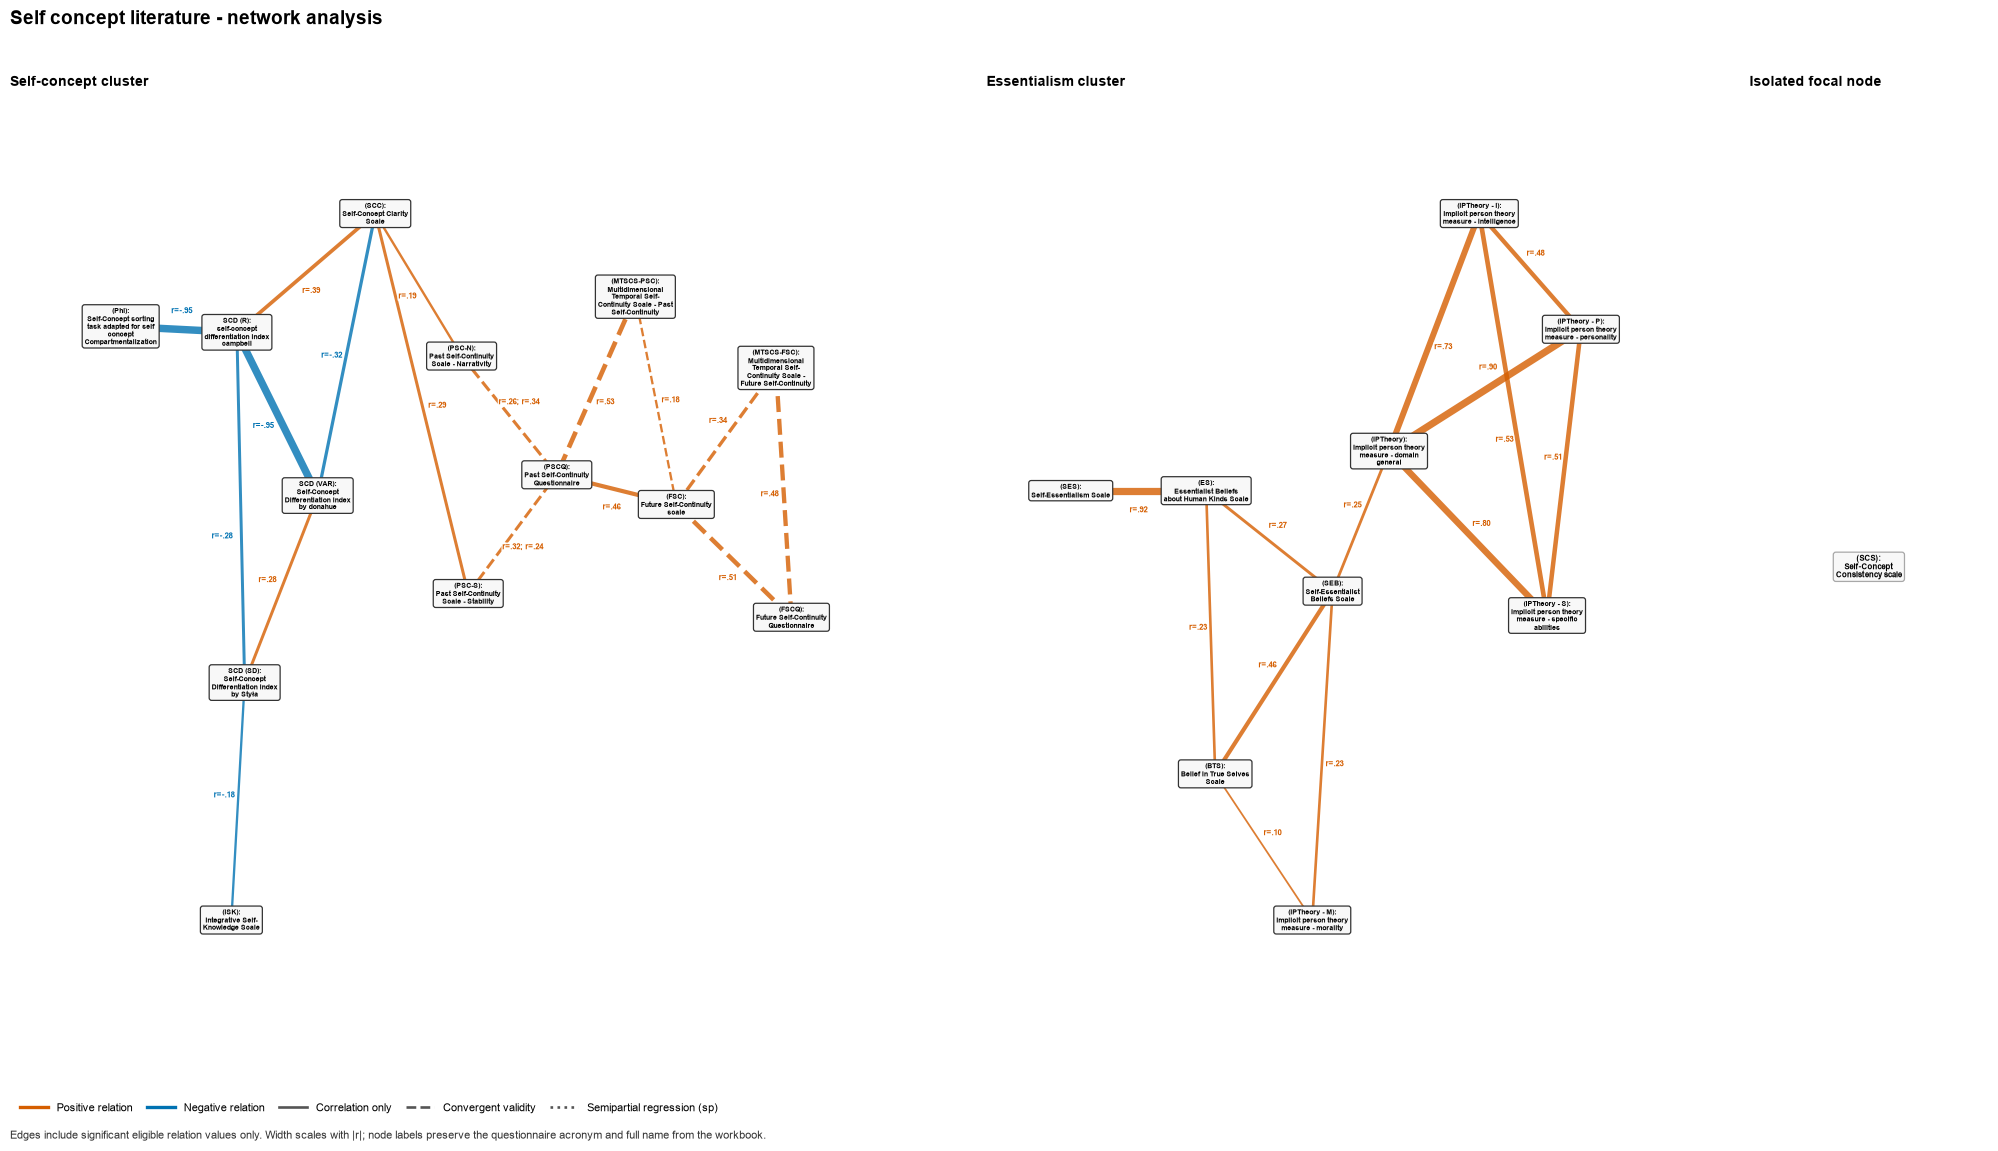

Saved PNG figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self_concept_cluster_network.png
Saved PDF figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self_concept_cluster_network.pdf
Saved SVG figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self_concept_cluster_network.svg


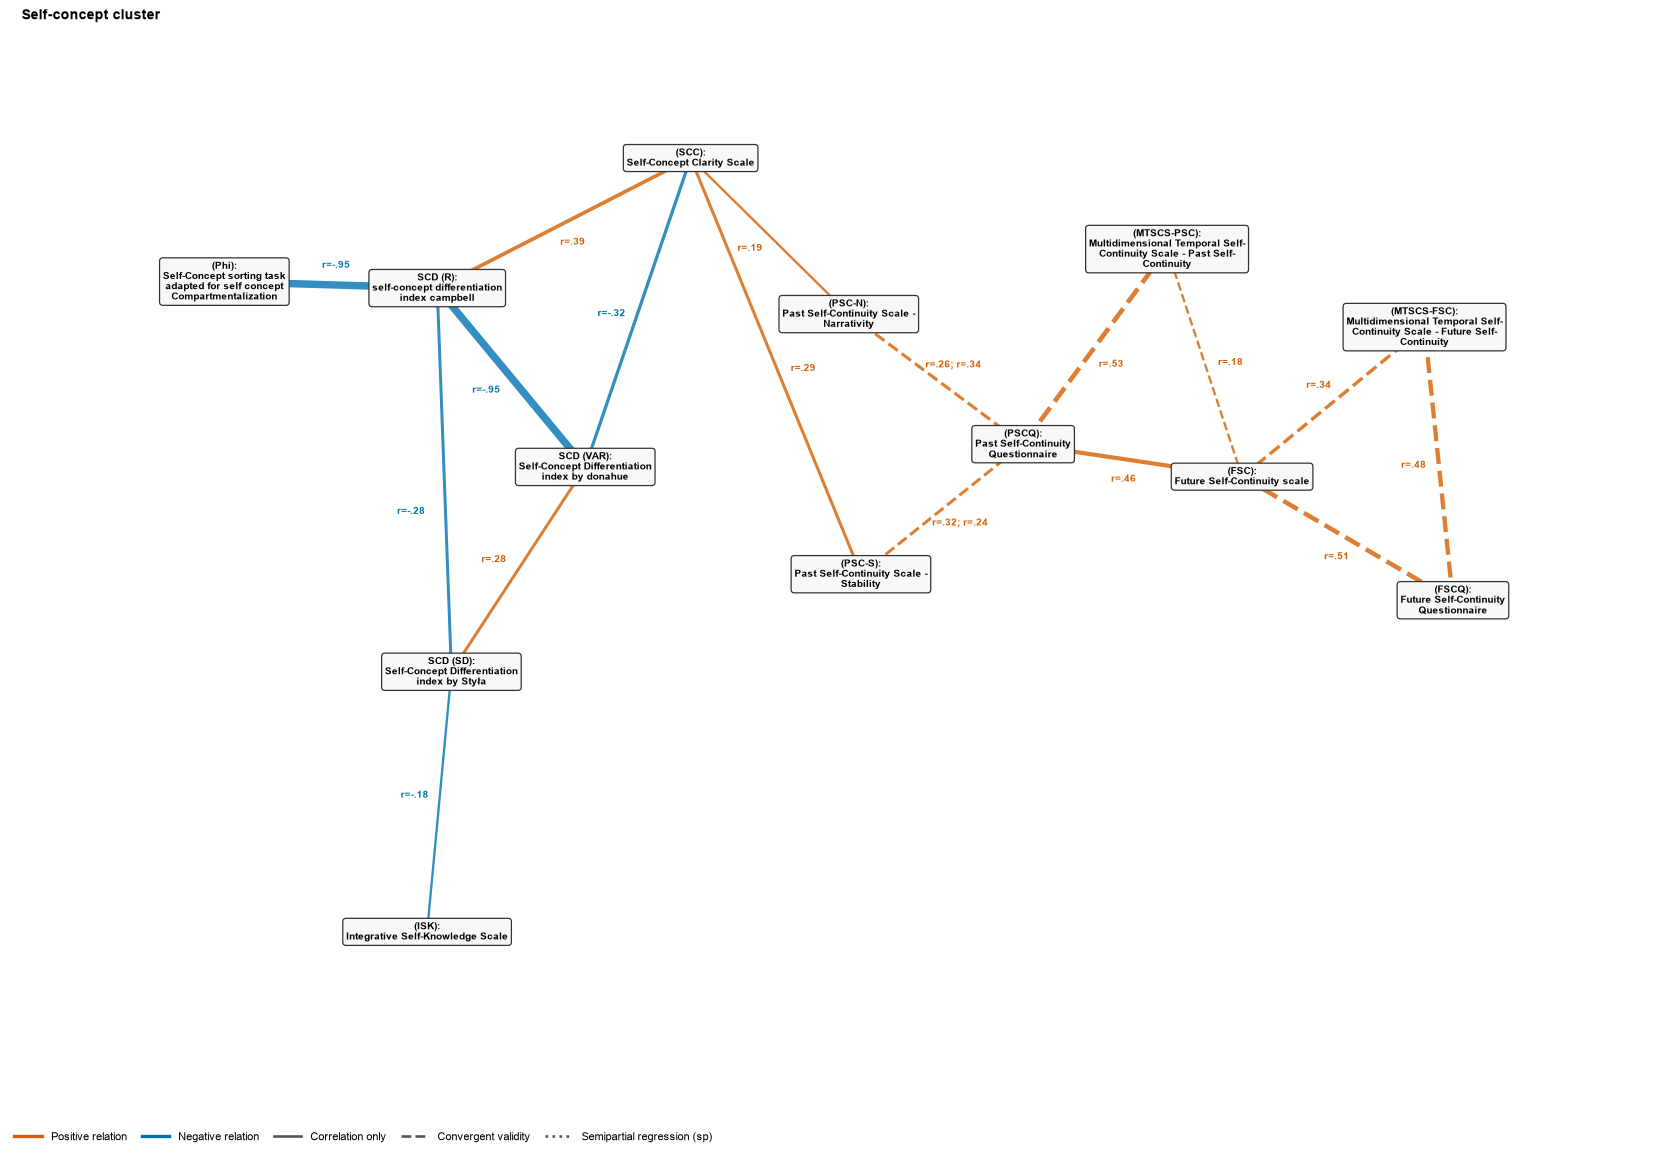

Saved PNG figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/essentialism_cluster_network.png
Saved PDF figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/essentialism_cluster_network.pdf
Saved SVG figure: /Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/essentialism_cluster_network.svg


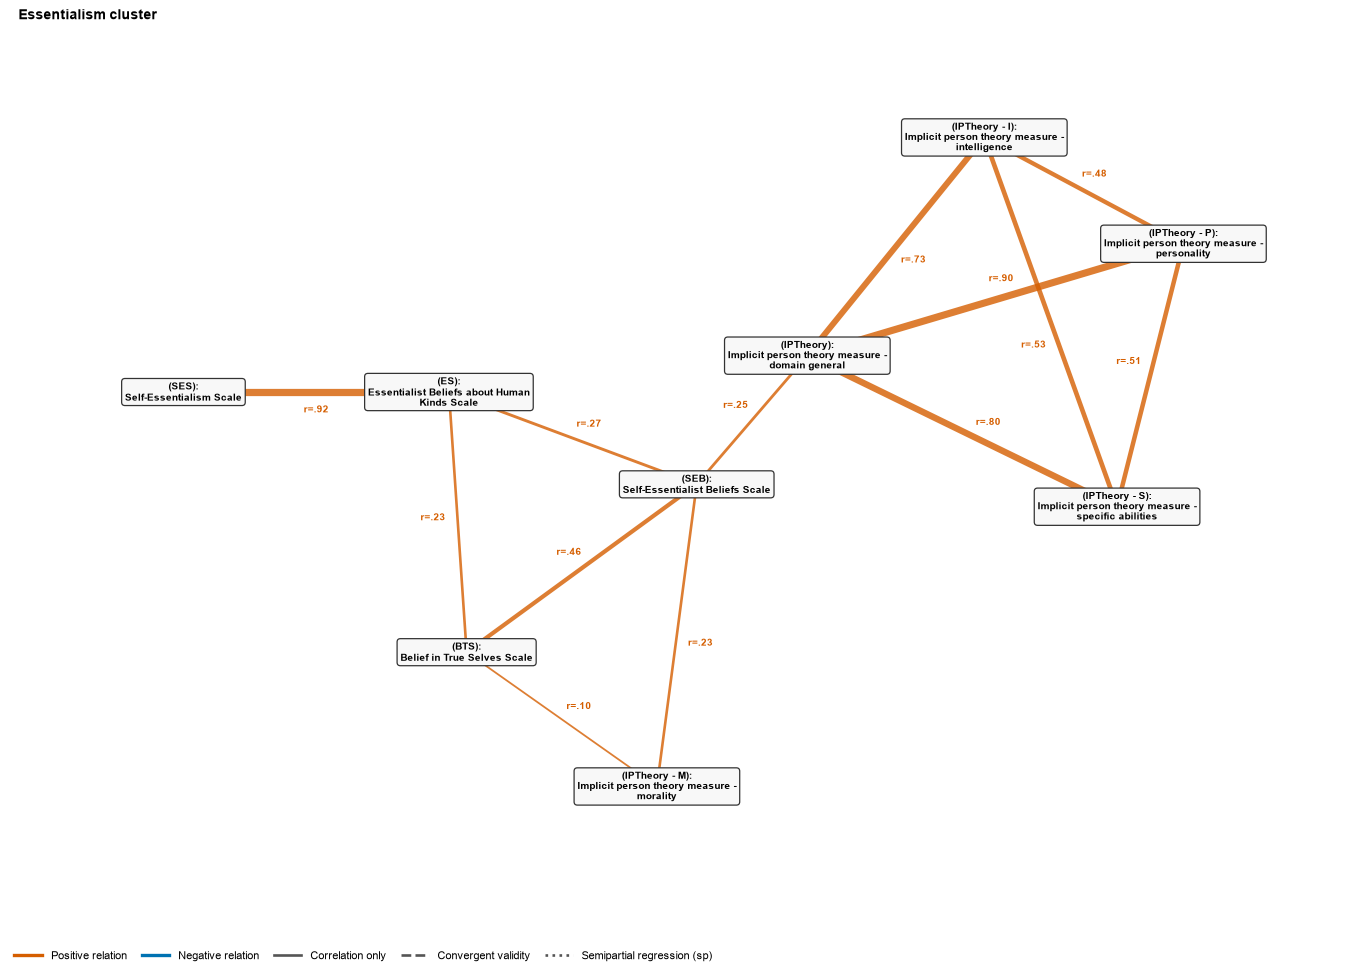

In [6]:
# Publication-oriented matplotlib settings.
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

POSITIVE_COLOR = "#D55E00"
NEGATIVE_COLOR = "#0072B2"
NODE_FACE = "#F8F8F8"
NODE_EDGE = "#333333"
ISOLATED_NODE_EDGE = "#A8A8A8"

components = sorted(nx.connected_components(G), key=lambda comp: (len(comp), sum(G.degree(node) for node in comp)), reverse=True)
isolated_components = [component for component in components if len(component) == 1]


def component_name(component):
    labels = " ".join(G.nodes[node]["label"].casefold() for node in component)
    if any(token in labels for token in ["essential", "iptheory", "implicit person", "true selves"]):
        return "Essentialism cluster"
    if len(component) > 1:
        return "Self-concept cluster"
    return "Isolated focal node"

cluster_components = {component_name(component): component for component in components}
self_concept_component = cluster_components.get("Self-concept cluster")
essentialism_component = cluster_components.get("Essentialism cluster")
isolated_component_nodes = set().union(*isolated_components) if isolated_components else set()

SELF_CONCEPT_LAYOUT = {
    "SCC": (0.00, 0.00),
    "SCD-R": (-1.25, -0.40),
    "Phi": (-2.30, -0.38),
    "SCD-VAR": (-0.52, -0.95),
    "SCD-SD": (-1.18, -1.58),
    "ISK": (-1.30, -2.38),
    "PSC-N": (0.78, -0.48),
    "PSC-S": (0.84, -1.28),
    "PSCQ": (1.64, -0.88),
    "MTSCS-PSC": (2.35, -0.28),
    "FSC": (2.72, -0.98),
    "MTSCS-FSC": (3.62, -0.52),
    "FSCQ": (3.76, -1.36),
}

ESSENTIALISM_LAYOUT = {
    "SES": (-1.70, 0.05),
    "ES": (-0.50, 0.05),
    "BTS": (-0.42, -0.88),
    "IPT-M": (0.44, -1.36),
    "SEB": (0.62, -0.28),
    "IPT": (1.12, 0.18),
    "IPT-I": (1.92, 0.96),
    "IPT-P": (2.82, 0.58),
    "IPT-S": (2.52, -0.36),
}

EDGE_LABEL_DISTANCE = 0.055

EDGE_LABEL_RULES = {
    frozenset(["SCD-SD", "SCD-R"]): (0.58, -0.075),
    frozenset(["SCD-SD", "SCD-VAR"]): (0.50, 0.060),
    frozenset(["SCD-R", "SCD-VAR"]): (0.50, -0.065),
    frozenset(["SCC", "SCD-VAR"]): (0.52, -EDGE_LABEL_DISTANCE),
    frozenset(["SCC", "PSC-N"]): (0.50, EDGE_LABEL_DISTANCE),
    frozenset(["SCC", "PSC-S"]): (0.48, -EDGE_LABEL_DISTANCE),
    frozenset(["PSC-N", "PSCQ"]): (0.50, EDGE_LABEL_DISTANCE),
    frozenset(["PSC-S", "PSCQ"]): (0.50, -EDGE_LABEL_DISTANCE),
    frozenset(["PSCQ", "MTSCS-PSC"]): (0.54, EDGE_LABEL_DISTANCE),
    frozenset(["FSC", "MTSCS-PSC"]): (0.48, -EDGE_LABEL_DISTANCE),
    frozenset(["MTSCS-FSC", "FSCQ"]): (0.50, EDGE_LABEL_DISTANCE),
    frozenset(["FSC", "FSCQ"]): (0.52, -EDGE_LABEL_DISTANCE),
    frozenset(["SES", "ES"]): (0.50, EDGE_LABEL_DISTANCE),
    frozenset(["BTS", "IPT-M"]): (0.50, EDGE_LABEL_DISTANCE),
    frozenset(["IPT-I", "IPT-P"]): (0.48, EDGE_LABEL_DISTANCE),
    frozenset(["IPT-P", "IPT-S"]): (0.54, EDGE_LABEL_DISTANCE),
    frozenset(["IPT-I", "IPT-S"]): (0.55, -EDGE_LABEL_DISTANCE),
    frozenset(["IPT", "IPT-P"]): (0.54, EDGE_LABEL_DISTANCE),
    frozenset(["IPT", "IPT-S"]): (0.54, EDGE_LABEL_DISTANCE),
    frozenset(["SEB", "IPT"]): (0.46, -EDGE_LABEL_DISTANCE),
}


def normalize_manual_positions(layout, subgraph, x_scale=1.0, y_scale=1.0):
    raw_pos = {}
    missing = []
    for node in subgraph.nodes:
        short = subgraph.nodes[node]["short_label"]
        if short in layout:
            raw_pos[node] = layout[short]
        else:
            missing.append(node)
    if missing:
        fallback = nx.spring_layout(subgraph.subgraph(missing), seed=42, k=1.2, iterations=1000, scale=1.0, weight=None)
        raw_pos.update(fallback)
    xs = [xy[0] for xy in raw_pos.values()]
    ys = [xy[1] for xy in raw_pos.values()]
    center_x = (min(xs) + max(xs)) / 2
    center_y = (min(ys) + max(ys)) / 2
    span_x = max(max(xs) - min(xs), 1e-6)
    span_y = max(max(ys) - min(ys), 1e-6)
    return {
        node: (((x - center_x) / span_x * 2.0 * x_scale), ((y - center_y) / span_y * 2.0 * y_scale))
        for node, (x, y) in raw_pos.items()
    }


def panel_positions(subgraph, cluster_title, x_scale=1.0, y_scale=1.0):
    if subgraph.number_of_nodes() == 1:
        return {next(iter(subgraph.nodes)): (0.0, 0.0)}
    if cluster_title == "Self-concept cluster":
        return normalize_manual_positions(SELF_CONCEPT_LAYOUT, subgraph, x_scale=x_scale, y_scale=y_scale)
    if cluster_title == "Essentialism cluster":
        return normalize_manual_positions(ESSENTIALISM_LAYOUT, subgraph, x_scale=x_scale, y_scale=y_scale)
    return nx.spring_layout(subgraph, seed=42, k=1.25, iterations=1200, scale=1.0, weight=None)


def draw_network_panel(
    ax,
    subgraph,
    title,
    label_width=28,
    node_font_size=6.2,
    edge_font_size=5.8,
    x_scale=1.0,
    y_scale=1.0,
):
    pos = panel_positions(subgraph, title, x_scale=x_scale, y_scale=y_scale)
    ax.set_title(title, loc="left", fontweight="bold", pad=8)
    ax.axis("off")
    ax.set_xlim(-1.33 * x_scale, 1.33 * x_scale)
    ax.set_ylim(-1.33 * y_scale, 1.33 * y_scale)

    for source_type, linestyle in [
        ("correlation_only", "-"),
        ("convergent_validity", "--"),
        ("regression_semipartial correlation", ":"),
    ]:
        edgelist = [
            (u, v) for u, v, data in subgraph.edges(data=True)
            if source_type in data["relation_source_type"].split("; ")
        ]
        if not edgelist:
            continue
        widths = [0.8 + 4.8 * subgraph.edges[edge]["abs_relation_value"] for edge in edgelist]
        colors = [subgraph.edges[edge]["color"] for edge in edgelist]
        nx.draw_networkx_edges(
            subgraph,
            pos,
            edgelist=edgelist,
            edge_color=colors,
            width=widths,
            style=linestyle,
            alpha=0.80,
            ax=ax,
        )

    for i, (source, target, data) in enumerate(subgraph.edges(data=True)):
        x1, y1 = pos[source]
        x2, y2 = pos[target]
        source_short = subgraph.nodes[source]["short_label"]
        target_short = subgraph.nodes[target]["short_label"]
        factor, offset = EDGE_LABEL_RULES.get(frozenset([source_short, target_short]), (0.52, EDGE_LABEL_DISTANCE))
        lx = x1 + (x2 - x1) * factor
        ly = y1 + (y2 - y1) * factor
        dx = x2 - x1
        dy = y2 - y1
        length = math.hypot(dx, dy) or 1.0
        lx -= dy / length * offset
        ly += dx / length * offset
        ax.text(
            lx,
            ly,
            data["label"],
            color=data["color"],
            fontsize=edge_font_size,
            fontweight="bold",
            ha="center",
            va="center",
            bbox={"boxstyle": "round,pad=0.10", "facecolor": "white", "edgecolor": "none", "alpha": 0.90},
            zorder=12,
        )

    for node, data in subgraph.nodes(data=True):
        x, y = pos[node]
        node_label = plot_node_label(data["label"], width=label_width)
        ax.text(
            x,
            y,
            node_label,
            ha="center",
            va="center",
            fontsize=node_font_size,
            fontweight="bold",
            linespacing=1.12,
            bbox={
                "boxstyle": "round,pad=0.34",
                "facecolor": NODE_FACE,
                "edgecolor": NODE_EDGE if subgraph.degree(node) > 0 else ISOLATED_NODE_EDGE,
                "linewidth": 0.9,
            },
            zorder=8,
        )


def add_figure_legend(fig, y=0.035, ncol=5):
    handles = [
        Line2D([0], [0], color=POSITIVE_COLOR, lw=2.4, label="Positive relation"),
        Line2D([0], [0], color=NEGATIVE_COLOR, lw=2.4, label="Negative relation"),
        Line2D([0], [0], color="#555555", lw=1.9, linestyle="-", label="Correlation only"),
        Line2D([0], [0], color="#555555", lw=1.9, linestyle="--", label="Convergent validity"),
        Line2D([0], [0], color="#555555", lw=1.9, linestyle=":", label="Semipartial regression (sp)"),
    ]
    fig.legend(
        handles=handles,
        loc="lower left",
        bbox_to_anchor=(0.02, y),
        frameon=False,
        fontsize=8,
        handlelength=2.5,
        ncol=ncol,
        columnspacing=1.3,
    )


def save_figure(fig, paths):
    fig.savefig(paths["png"], dpi=600, bbox_inches="tight", facecolor="white")
    fig.savefig(paths["pdf"], bbox_inches="tight", facecolor="white")
    fig.savefig(paths["svg"], bbox_inches="tight", facecolor="white")
    for fmt, path in paths.items():
        print(f"Saved {fmt.upper()} figure: {path}")

# Combined figure: two large cluster panels plus isolated node panel.
fig = plt.figure(figsize=(20.5, 11.6))
fig.patch.set_facecolor("white")
grid = fig.add_gridspec(
    nrows=1,
    ncols=3,
    width_ratios=[1.42, 1.08, 0.38],
    wspace=0.14,
)
axes = [fig.add_subplot(grid[0, col]) for col in range(3)]
fig.suptitle(GRAPH_TITLE, x=0.02, y=0.985, ha="left", va="top", fontweight="bold", fontsize=14)

if self_concept_component:
    draw_network_panel(
        axes[0],
        G.subgraph(self_concept_component).copy(),
        "Self-concept cluster",
        label_width=23,
        node_font_size=5.25,
        edge_font_size=5.45,
        x_scale=1.30,
        y_scale=1.05,
    )
else:
    axes[0].axis("off")

if essentialism_component:
    draw_network_panel(
        axes[1],
        G.subgraph(essentialism_component).copy(),
        "Essentialism cluster",
        label_width=23,
        node_font_size=5.25,
        edge_font_size=5.45,
        x_scale=1.12,
        y_scale=1.00,
    )
else:
    axes[1].axis("off")

if isolated_component_nodes:
    draw_network_panel(
        axes[2],
        G.subgraph(isolated_component_nodes).copy(),
        "Isolated focal node",
        label_width=20,
        node_font_size=5.5,
        edge_font_size=5.2,
    )
else:
    axes[2].axis("off")

add_figure_legend(fig, y=0.025, ncol=5)
fig.text(
    0.02,
    0.010,
    "Edges include significant eligible relation values only. Width scales with |r|; node labels preserve the questionnaire acronym and full name from the workbook.",
    ha="left",
    va="bottom",
    fontsize=8,
    color="#333333",
)
fig.subplots_adjust(left=0.02, right=0.985, top=0.91, bottom=0.10)
save_figure(fig, COMBINED_GRAPH_PATHS)
plt.show()

# Separate self-concept cluster figure.
if self_concept_component:
    fig_self, ax_self = plt.subplots(figsize=(17.2, 12.4))
    fig_self.patch.set_facecolor("white")
    draw_network_panel(
        ax_self,
        G.subgraph(self_concept_component).copy(),
        "Self-concept cluster",
        label_width=32,
        node_font_size=7.0,
        edge_font_size=6.9,
        x_scale=1.34,
        y_scale=1.08,
    )
    add_figure_legend(fig_self, y=0.025, ncol=5)
    fig_self.subplots_adjust(left=0.03, right=0.98, top=0.93, bottom=0.10)
    save_figure(fig_self, SELF_CONCEPT_CLUSTER_PATHS)
    plt.show()

# Separate essentialism cluster figure.
if essentialism_component:
    fig_essential, ax_essential = plt.subplots(figsize=(14.0, 10.4))
    fig_essential.patch.set_facecolor("white")
    draw_network_panel(
        ax_essential,
        G.subgraph(essentialism_component).copy(),
        "Essentialism cluster",
        label_width=32,
        node_font_size=7.0,
        edge_font_size=6.9,
        x_scale=1.12,
        y_scale=1.00,
    )
    add_figure_legend(fig_essential, y=0.025, ncol=5)
    fig_essential.subplots_adjust(left=0.03, right=0.98, top=0.93, bottom=0.10)
    save_figure(fig_essential, ESSENTIALISM_CLUSTER_PATHS)
    plt.show()


## 7. Output Review

The files below are the expected reproducible outputs from the notebook. No interactive HTML graph is generated.


In [7]:
expected_paths = [
    *COMBINED_GRAPH_PATHS.values(),
    *SELF_CONCEPT_CLUSTER_PATHS.values(),
    *ESSENTIALISM_CLUSTER_PATHS.values(),
    CLEANED_EDGES_PATH,
    NODE_LIST_PATH,
    NODE_LABEL_KEY_PATH,
    EXCLUDED_ROWS_QA_PATH,
    EXCLUDED_NON_FOCAL_PATH,
]
for path in expected_paths:
    print(path, "exists=", path.exists())


/Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self questionnaires mapping network.png exists= True
/Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self questionnaires mapping network.pdf exists= True
/Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self questionnaires mapping network.svg exists= True
/Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self_concept_cluster_network.png exists= True
/Users/dotanshani/Desktop/neuroscience Ms.c/Self-Reification Questionnaire Mapping Project/questionnaire_mapping_network_analysis/outputs/figures/self_concept_cluster_network.pdf exists= True
/Users/dotanshani/D